In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean_hourly.csv", index_col=0, parse_dates=True)
print(df.shape)
df.head()

(17544, 15)


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
datetime,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,1,0,0,6,0,1.0,0.24,0.2879,0.81,0.0,3.0,13.0,16.0
2011-01-01 01:00:00,1,0,1,1,0,6,0,1.0,0.22,0.2727,0.80,0.0,8.0,32.0,40.0
2011-01-01 02:00:00,1,0,1,2,0,6,0,1.0,0.22,0.2727,0.80,0.0,5.0,27.0,32.0
2011-01-01 03:00:00,1,0,1,3,0,6,0,1.0,0.24,0.2879,0.75,0.0,3.0,10.0,13.0
2011-01-01 04:00:00,1,0,1,4,0,6,0,1.0,0.24,0.2879,0.75,0.0,0.0,1.0,1.0


In [2]:
def mae(actual, pred):
    return np.mean(np.abs(actual - pred))

def rmse(actual, pred):
    return np.sqrt(np.mean((actual - pred) ** 2))

In [3]:
# Baseline 1: same hour yesterday
df["pred_naive_24"] = df["cnt"].shift(24)

# Baseline 2: same hour last week
df["pred_naive_168"] = df["cnt"].shift(168)

In [4]:
train = df.loc[:"2012-06-30"].copy()
test = df.loc["2012-07-01":].copy()

print("Train:", train.index.min(), "to", train.index.max(), "->", len(train))
print("Test: ", test.index.min(), "to", test.index.max(), "->", len(test))

Train: 2011-01-01 00:00:00 to 2012-06-30 23:00:00 -> 13128
Test:  2012-07-01 00:00:00 to 2012-12-31 23:00:00 -> 4416


In [5]:
# average rentals for each (workingday, hour) combination, using ONLY train data
avg_profile = train.groupby(["workingday", "hr"])["cnt"].mean()

test["pred_avg"] = [avg_profile[(w, h)] for w, h in zip(test["workingday"], test["hr"])]

In [6]:
results = []
for name in ["pred_naive_24", "pred_naive_168", "pred_avg"]:
    results.append({
        "model": name,
        "MAE": mae(test["cnt"], test[name]),
        "RMSE": rmse(test["cnt"], test[name]),
    })

results_df = pd.DataFrame(results)
print(results_df)
results_df.to_csv("../results/baseline_results.csv", index=False)

            model         MAE        RMSE
0   pred_naive_24   80.447464  134.516748
1  pred_naive_168   65.957201  114.939594
2        pred_avg  107.831616  151.114916


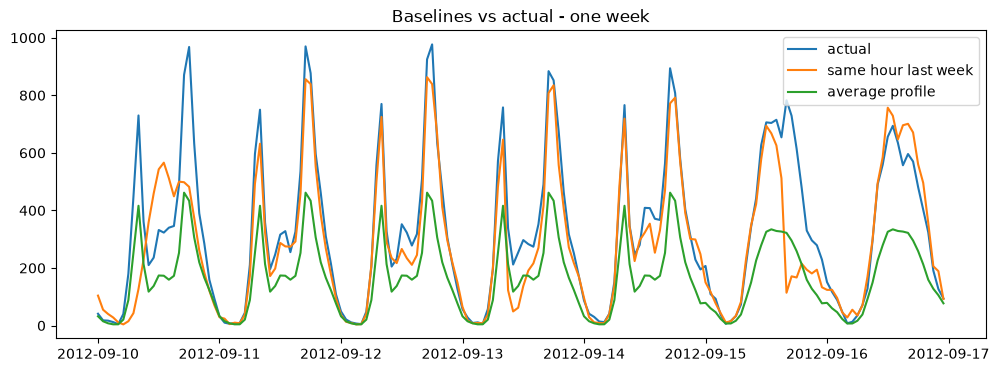

In [7]:
week = test.loc["2012-09-10":"2012-09-16"]

plt.figure(figsize=(12, 4))
plt.plot(week["cnt"], label="actual")
plt.plot(week["pred_naive_168"], label="same hour last week")
plt.plot(week["pred_avg"], label="average profile")
plt.legend()
plt.title("Baselines vs actual - one week")
plt.savefig("../results/baseline_week.png")
plt.show()